<a href="https://colab.research.google.com/github/Tobkubos/Systemy_AI/blob/main/SystemyAI_TobiaszKubiak_Lab5_Cukrzyca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [108]:
# Twoje rozwiązanie
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)

df.shape
df.head()
df.describe()



,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [109]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64
pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64


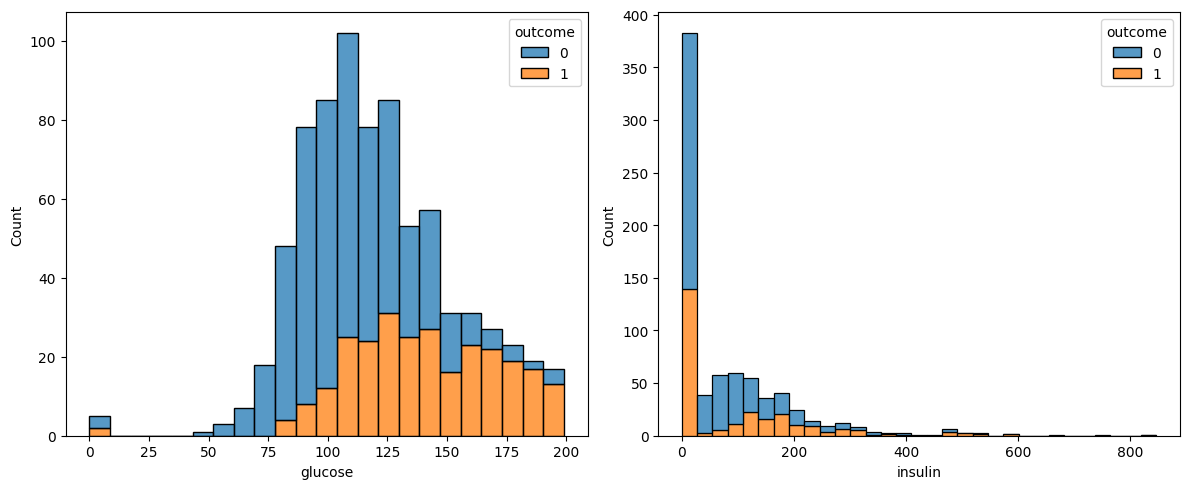

In [110]:
# Twoje rozwiązanie

# UDZIAŁ KALS
class_share = df["outcome"].value_counts(normalize=True)
print(class_share)

# CZY SĄ BRAKI
print(df.isna().sum())

# ZLICZENIE ZER
zeros = (df == 0).sum()

# WYKRES
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0], multiple="stack")
sns.histplot(data=df, x="insulin", hue="outcome", ax=axes[1], multiple="stack")

plt.tight_layout()
plt.show()

In [111]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

In [112]:
# 1. Baseline - DummyClassifier - 0.65 (wynika to z class_share)
#
# 2.
# Niemożliwe: glucose, blood_pressure, skin_thickness, bmi, insulin
# Normalne: pregnacies
#
# 3. Glucose – zdrowe pacjentki do wartości np. 125, chore mają znacznie wyższe stężenie (większe niż 140–160).

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [113]:
df_clean = df.copy()

for col in ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]:
    df_clean[col] = df_clean[col].replace(0, np.nan)

missing = df_clean.isna().sum()

In [114]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

In [115]:
# Możliwości:
# - Usunięcie wierszy z brakami
# - Zastąpienie braków średnią/medianą
#
# Wybór:
# - Zastąpienie braków medianą, zbiór jest zbyt mały, a ilość wierszy z brakami zbyt duża aby je odrzucać.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [116]:
# Twoje rozwiązanie
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df_clean.drop("outcome", axis=1)
y = df_clean["outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

def model_z(klasyfikator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("klasyfikator", klasyfikator)
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [117]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

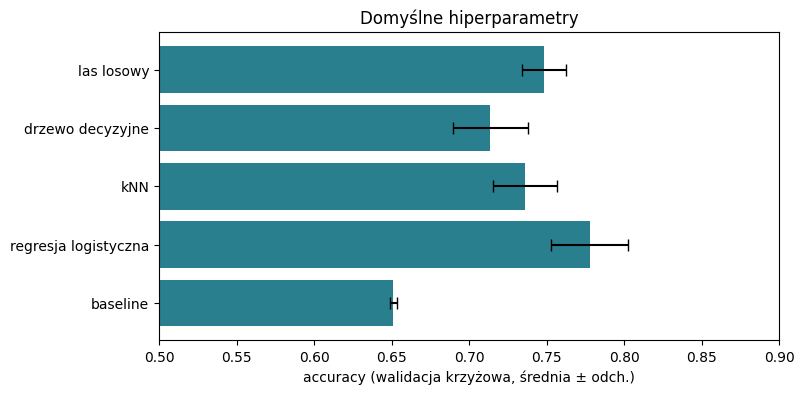

In [118]:
# Twoje rozwiązanie
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

models = [
    DummyClassifier(strategy="most_frequent"),
    LogisticRegression(),
    KNeighborsClassifier(),
    DecisionTreeClassifier(random_state=42),
    RandomForestClassifier(random_state=42)
]

porownanie = pd.DataFrame(index=["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"], columns=["CV średnia", "CV odch.", "train"])

for i, model in enumerate(models):
    model_pipeline = model_z(model)

    cv_scores = cross_val_score(model_pipeline, X_train, y_train, cv=cv)

    porownanie.loc[porownanie.index[i], "CV średnia"] = cv_scores.mean()
    porownanie.loc[porownanie.index[i], "CV odch."] = cv_scores.std()

    model_pipeline.fit(X_train, y_train)

    porownanie.loc[porownanie.index[i], "train"] = model_pipeline.score(X_train, y_train)

porownanie = porownanie.astype(float)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(porownanie.index, porownanie["CV średnia"], xerr=porownanie["CV odch."], capsize=4, color="#2a7f8f")
ax.set_xlim(0.5, 0.9)
ax.set_xlabel("accuracy (walidacja krzyżowa, średnia ± odch.)")
ax.set_title("Domyślne hiperparametry")
plt.show()


In [119]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

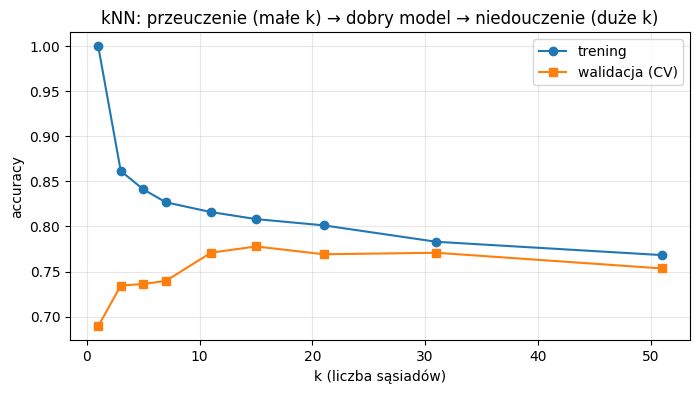

,1,3,5,7,11,15,21,31,51
trening,1.000,0.862,0.841,0.827,0.816,0.808,0.801,0.783,0.768
walidacja,0.689,0.734,0.736,0.740,0.771,0.778,0.769,0.771,0.753


In [120]:
# Twoje rozwiązanie
from sklearn.model_selection import validation_curve

ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]

# PIPELINE
pipeline = model_z(KNeighborsClassifier())

# VALIDATION CURVE
tren, walid = validation_curve(pipeline, X_train, y_train,
    param_name="klasyfikator__n_neighbors", param_range=ks, cv=cv, scoring="accuracy")

# WYKRES
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, tren.mean(axis=1), "o-", label="trening")
ax.plot(ks, walid.mean(axis=1), "s-", label="walidacja (CV)")
ax.set_xlabel("k (liczba sąsiadów)")
ax.set_ylabel("accuracy")
ax.set_title("kNN: przeuczenie (małe k) → dobry model → niedouczenie (duże k)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame({"trening": tren.mean(axis=1), "walidacja": walid.mean(axis=1)}, index=ks).round(3).T

In [121]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

1. dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0?
Algorytm dla każdego punktu ze zbioru treningowego znajduje najbliższego sąsiada. Dla k = 1, przypisuje mu więc dokładnie jego własną etykietę, uzyskując 100% poprawnych odpowiedzi.

2. Przeuczenie
Występuje dla bardzo małych k - analogicznie do powyższej wypowiedzi, można powiedzieć, że algorytm wkuwa odpowiedzi na pamięć.
Model ma idealne wyniki na zbiorze treningowym, ale słabsze na walidacyjnym, nie potrafi dopasować odpowedzi.

3. Niedouczenie
Występuje dla bardzo dużych k. Granica decyzyjna staje się zbyt wygładzona.Model uśrednia zbyt wielu sąsiadów i zaczyna po prostu głosować na klasę większościową, przez co wyniki spadają na treningu i walidacji.

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [122]:
# Twoje rozwiązanie
from sklearn.model_selection import GridSearchCV

siatki = {
    "regresja logistyczna": (
        LogisticRegression(),
        {"klasyfikator__C": [0.01, 0.1, 1, 10, 100]}
    ),
    "kNN": (
        KNeighborsClassifier(),
        {"klasyfikator__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}
    ),
    "drzewo decyzyjne": (
        DecisionTreeClassifier(random_state=42),
        {"klasyfikator__max_depth": [2, 3, 4, 5, 6, 8, None]}
    ),
    "las losowy": (
        RandomForestClassifier(random_state=42),
        {"klasyfikator__max_depth": [3, 5, 8, None], "klasyfikator__n_estimators": [100, 300]}
    )
}

wyniki_gs = {}

for model_nazwa, (model, siatka) in siatki.items():
    gs = GridSearchCV(model_z(model), siatka, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs[model_nazwa] = gs

    std = gs.cv_results_["std_test_score"][gs.best_index_]

    print(f"{model_nazwa:22s} najlepsze: {gs.best_params_}  CV = {gs.best_score_:.3f}  STD = {std:.3f}")
    print()

regresja logistyczna   najlepsze: {'klasyfikator__C': 1}  CV = 0.778  STD = 0.025

kNN                    najlepsze: {'klasyfikator__n_neighbors': 15}  CV = 0.778  STD = 0.036

drzewo decyzyjne       najlepsze: {'klasyfikator__max_depth': 5}  CV = 0.750  STD = 0.011

las losowy             najlepsze: {'klasyfikator__max_depth': 3, 'klasyfikator__n_estimators': 300}  CV = 0.762  STD = 0.015



In [123]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

wybrany model: regresja logistyczna {'klasyfikator__C': 1}
szacunek z CV:   0.778
wynik na teście: 0.724


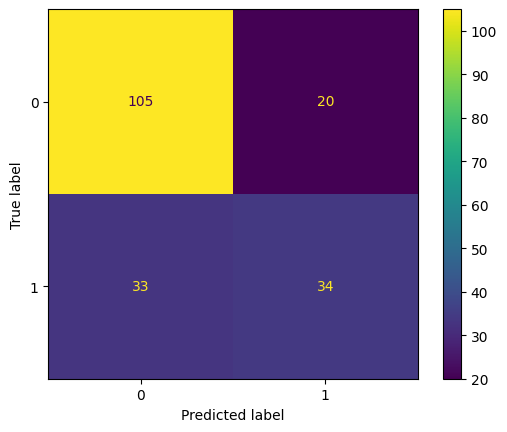

              precision    recall  f1-score   support

           0       0.76      0.84      0.80       125
           1       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192



In [124]:
# Twoje rozwiązanie
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
print("wybrany model:", najlepszy, wyniki_gs[najlepszy].best_params_)
print(f"szacunek z CV:   {wyniki_gs[najlepszy].best_score_:.3f}")
print(f"wynik na teście: {model_koncowy.score(X_test, y_test):.3f}")

acc_test = model_koncowy.score(X_test, y_test)
y_pred = model_koncowy.predict(X_test)

ConfusionMatrixDisplay.from_estimator(model_koncowy, X_test, y_test)
plt.show()
print(classification_report(y_test, y_pred))

In [125]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

In [126]:
# 1. Wynik testowy 72.4% jest niższy od średniej z CV 77.8% o 5.4 p.p.
# Zbiór testowy liczy 192 pacjentki, więc jedna osoba to ok. 0.52% (1/192).
# Różnica ta odpowiada ok. 11-12 osobom. Taki spadek nie jest niepokojący,
# patrząc na wielkość zbioru danych.
#
# 2. Recall dla klasy "cukrzyca" wynosi tylko 51%.
# Dla pacjentek oznacza to, że niemal połowa chorych nie zostanie wykryta.
# Accuracy nie jest dobrą metryką, ponieważ dużo ważniejsze jest nie wykrycie cukrzycy niż jej wykrycie.
# Powinno się optymalizować model poprzez metrykę recall.
#
# 3. Nie można jednoznacznie wskazać najlepszego algorytmu.
# Różnice są na tyle małe, że można powiedzieć, że wyniki są tożsame.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

regresja logistyczna   najlepsze: {'klasyfikator__C': 1}  CV (recall) = 0.583 ± 0.053

kNN                    najlepsze: {'klasyfikator__n_neighbors': 3}  CV (recall) = 0.597 ± 0.089

drzewo decyzyjne       najlepsze: {'klasyfikator__max_depth': 4}  CV (recall) = 0.652 ± 0.128

las losowy             najlepsze: {'klasyfikator__max_depth': None, 'klasyfikator__n_estimators': 100}  CV (recall) = 0.582 ± 0.062


Wybrany model (recall): drzewo decyzyjne {'klasyfikator__max_depth': 4}
Szacunek z CV (recall): 0.652


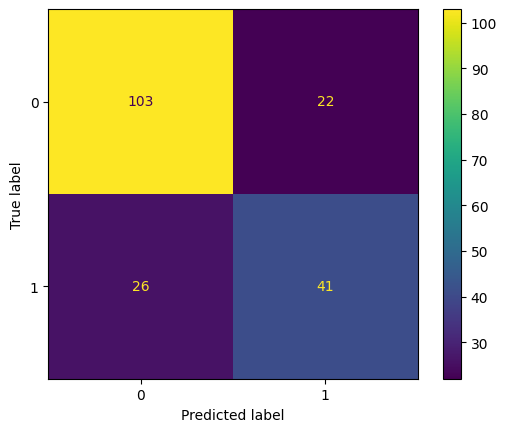

              precision    recall  f1-score   support

           0       0.80      0.82      0.81       125
           1       0.65      0.61      0.63        67

    accuracy                           0.75       192
   macro avg       0.72      0.72      0.72       192
weighted avg       0.75      0.75      0.75       192

(flagi braków ) regresja logistyczna   najlepsze: {'klasyfikator__C': 0.1}  CV = 0.769 ± 0.062
(flagi braków ) kNN                    najlepsze: {'klasyfikator__n_neighbors': 11}  CV = 0.757 ± 0.062
(flagi braków ) drzewo decyzyjne       najlepsze: {'klasyfikator__max_depth': 5}  CV = 0.752 ± 0.062
(flagi braków ) las losowy             najlepsze: {'klasyfikator__max_depth': 8, 'klasyfikator__n_estimators': 100}  CV = 0.759 ± 0.062

(zera zamiast NaN )regresja logistyczna   najlepsze: {'klasyfikator__C': 10}  CV = 0.780 ± 0.062
(zera zamiast NaN )kNN                    najlepsze: {'klasyfikator__n_neighbors': 11}  CV = 0.755 ± 0.062
(zera zamiast NaN )drzewo decyzy

In [129]:
# 1. GridSearchCV
wyniki_gs_recall = {}

for model_nazwa, (model, siatka) in siatki.items():
    gs = GridSearchCV(model_z(model), siatka, cv=cv, scoring="recall")
    gs.fit(X_train, y_train)
    wyniki_gs_recall[model_nazwa] = gs

    std = gs.cv_results_["std_test_score"][gs.best_index_]
    print(f"{model_nazwa:22s} najlepsze: {gs.best_params_}  CV (recall) = {gs.best_score_:.3f} ± {std:.3f}")
    print()

scores_recall = {nazwa: gs.best_score_ for nazwa, gs in wyniki_gs_recall.items()}
najlepszy_recall = max(scores_recall, key=scores_recall.get)
model_koncowy_recall = wyniki_gs_recall[najlepszy_recall].best_estimator_
print(f"\nWybrany model (recall): {najlepszy_recall} {wyniki_gs_recall[najlepszy_recall].best_params_}")
print(f"Szacunek z CV (recall): {wyniki_gs_recall[najlepszy_recall].best_score_:.3f}")

y_pred_recall = model_koncowy_recall.predict(X_test)

ConfusionMatrixDisplay.from_estimator(model_koncowy_recall, X_test, y_test)
plt.show()
print(classification_report(y_test, y_pred_recall))

# 2. add_incidator=True
def model_z_indicator(klasyfikator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("klasyfikator", klasyfikator)
    ])

for model_nazwa, (model, siatka) in siatki.items():
    gs = GridSearchCV(model_z_indicator(model), siatka, cv=cv)
    gs.fit(X_train, y_train)
    print(f"(flagi braków ) {model_nazwa:22s} najlepsze: {gs.best_params_}  CV = {gs.best_score_:.3f} ± {std:.3f}")
print()

# 3. Zostawienie zer zamiast NaN
X_surowe = df.drop("outcome", axis=1)
y_surowe = df["outcome"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_surowe, y_surowe, test_size=0.25, stratify=y_surowe, random_state=42
)

for model_nazwa, (model, siatka) in siatki.items():
    gs = GridSearchCV(model_z(model), siatka, cv=cv)
    gs.fit(X_train_s, y_train_s)
    print(f"(zera zamiast NaN ){model_nazwa:22s} najlepsze: {gs.best_params_}  CV = {gs.best_score_:.3f} ± {std:.3f}")

In [128]:
# Czy zmienił się wybrany model? Co stało się z precision?
# Wybrany model się zmienił na drzewo decyzyjne
# Recall wzrósł z 51% do 61% (wykryto 41 chorych zamiast 34).
# Precision wzrosło z 63% do 65%,
# liczba fałszywych alarmów FP wzrosła z 20 do 22.
#
# Czy sam fakt braku pomiaru insuliny niesie informację?
# Tak, sam fakt braku niesie informację, wynik modelu minimalnie się zmienia.
#
# Czy różnica jest duża? Dlaczego może być mała?
# Różnica w wynikach jest bardzo mała, ponieważ
# Ilość rekordów z brakującymi cechami tj.: glukoza, wiek, BMI jest niska